# 07. Hồi quy tuyến tính dự báo doanh thu

**Issue #6** – Chuyển sang mức **Dự đoán (Predictive)** theo lộ trình khóa học (Tuần 10 – Linear Regression).

### Mục tiêu
- Xây dựng mô hình **Linear Regression** dự báo doanh thu
- Đánh giá bằng R², MAE, RMSE và biểu đồ
- Giải thích hệ số hồi quy theo góc nhìn kinh doanh

### Biến mục tiêu
- `Log_Sales = log(1 + Sales)` — giảm ảnh hưởng phân phối lệch phải


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Set2")
print("Đã import thư viện thành công")


Đã import thư viện thành công


## 1. Đọc dữ liệu đã xử lý
Ưu tiên `data/processed/superstore_cleaned.csv`. Nếu không có, fallback sang `data/raw/train.csv`.


In [3]:
# Tìm file dữ liệu (chạy được cả từ notebooks/ lẫn thư mục gốc)
candidates = [
    "../data/processed/superstore_cleaned.csv",
    "data/processed/superstore_cleaned.csv",
    "../data/raw/train.csv",
    "data/raw/train.csv",
    "train.csv",
]

df = None
used_path = None
for path in candidates:
    if os.path.exists(path):
        df = pd.read_csv(path)
        used_path = path
        break

if df is None:
    raise FileNotFoundError(
        "Không tìm thấy file dữ liệu. Hãy đảm bảo có data/processed/superstore_cleaned.csv hoặc data/raw/train.csv"
    )

df.columns = [c.strip() for c in df.columns]
print(f"Đã đọc: {used_path}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print("Các cột:", df.columns.tolist())
df.head(3)


Đã đọc: ../data/processed/superstore_cleaned.csv
Kích thước: 9,789 dòng × 31 cột
Các cột: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Year', 'Month', 'Quarter', 'DayOfWeek', 'Is_Weekend', 'Ship_Days', 'Cust_Order_Count', 'Cust_Item_Count', 'Cust_Mean_Sales', 'SubCat_Mean_Sales', 'Is_Outlier', 'Log_Sales', 'Sales_Capped']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,Quarter,DayOfWeek,Is_Weekend,Ship_Days,Cust_Order_Count,Cust_Item_Count,Cust_Mean_Sales,SubCat_Mean_Sales,Is_Outlier,Log_Sales,Sales_Capped
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2017,11,4,Wednesday,0,3,3,5,229.756,486.259105,0,5.572002,261.960
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,2017,11,4,Wednesday,0,3,3,5,229.756,531.530579,1,6.597064,500.108
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2017,6,2,Monday,0,4,5,9,124.387,34.587468,0,2.748552,14.620


## 2. Tạo biến cần thiết (nếu thiếu)
- `Month`, `Ship_Days` từ ngày đặt / ngày giao
- `Log_Sales = log1p(Sales)`


In [4]:
# Parse ngày
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], dayfirst=True, errors="coerce")

# Month
if "Month" not in df.columns and "Order Date" in df.columns:
    df["Month"] = df["Order Date"].dt.month

# Ship_Days
if "Ship_Days" not in df.columns and {"Order Date", "Ship Date"}.issubset(df.columns):
    df["Ship_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Log_Sales
if "Sales" not in df.columns:
    raise KeyError("Không tìm thấy cột Sales")
df["Log_Sales"] = np.log1p(df["Sales"])

# Loại dòng thiếu biến bắt buộc
required = ["Sales", "Category", "Region", "Segment"]
optional_num = [c for c in ["Month", "Ship_Days"] if c in df.columns]
df = df.dropna(subset=required + optional_num).copy()

# Ship_Days âm (lỗi ngày) → loại
if "Ship_Days" in df.columns:
    df = df[df["Ship_Days"] >= 0].copy()

print("Shape sau làm sạch:", df.shape)
print(df[["Sales", "Log_Sales", "Category", "Region", "Segment"] + optional_num].describe(include="all").T)


Shape sau làm sạch: (9789, 31)
            count unique              top  freq        mean         std  \
Sales      9789.0    NaN              NaN   NaN  230.116193  625.302079   
Log_Sales  9789.0    NaN              NaN   NaN    4.156481    1.590884   
Category     9789      3  Office Supplies  5903         NaN         NaN   
Region       9789      4             West  3140         NaN         NaN   
Segment      9789      3         Consumer  5096         NaN         NaN   
Month      9789.0    NaN              NaN   NaN    7.822658    3.277864   
Ship_Days  9789.0    NaN              NaN   NaN    3.961181    1.750452   

                min       25%       50%       75%        max  
Sales         0.444    17.248    54.384   210.392   22638.48  
Log_Sales  0.367417  2.904055  4.014291  5.353714  10.027451  
Category        NaN       NaN       NaN       NaN        NaN  
Region          NaN       NaN       NaN       NaN        NaN  
Segment         NaN       NaN       NaN       NaN    

## 3. Chọn biến độc lập (X) và biến mục tiêu (y)

| Vai trò | Biến | Lý do |
|---------|------|--------|
| Mục tiêu | `Log_Sales` | Giảm lệch phải của Sales |
| Phân loại | `Category`, `Region`, `Segment` | Yếu tố kinh doanh chính từ EDA/Diagnostic |
| Số | `Month`, `Ship_Days` (nếu có) | Thời vụ và vận hành |


In [5]:
cat_cols = ["Category", "Region", "Segment"]
num_cols = [c for c in ["Month", "Ship_Days"] if c in df.columns]

# Kiểm tra cột tồn tại
for c in cat_cols:
    if c not in df.columns:
        raise KeyError(f"Thiếu cột phân loại: {c}")

X = df[cat_cols + num_cols].copy()
y = df["Log_Sales"].copy()

print("Biến phân loại:", cat_cols)
print("Biến số:", num_cols)
print("X:", X.shape, "| y:", y.shape)
print("\nMissing trong X:")
print(X.isna().sum())
print("\nPhân phối Category / Region / Segment:")
for c in cat_cols:
    print(f"  {c}: {X[c].nunique()} mức → {list(X[c].unique())}")


Biến phân loại: ['Category', 'Region', 'Segment']
Biến số: ['Month', 'Ship_Days']
X: (9789, 5) | y: (9789,)

Missing trong X:
Category     0
Region       0
Segment      0
Month        0
Ship_Days    0
dtype: int64

Phân phối Category / Region / Segment:
  Category: 3 mức → ['Furniture', 'Office Supplies', 'Technology']
  Region: 4 mức → ['South', 'West', 'Central', 'East']
  Segment: 3 mức → ['Consumer', 'Corporate', 'Home Office']


## 4. Chia tập train / test (80/20)
`random_state=42` để tái lập kết quả.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]:,} dòng")
print(f"Test : {X_test.shape[0]:,} dòng")


Train: 7,831 dòng
Test : 1,958 dòng


## 5. One-Hot Encoding + Linear Regression
Dùng `Pipeline` để encode và huấn luyện trong một quy trình, tránh rò rỉ thông tin từ test.


In [7]:
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols),
    ]
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("lr", LinearRegression()),
])

model.fit(X_train, y_train)
print("Đã huấn luyện xong Linear Regression")


Đã huấn luyện xong Linear Regression


## 6. Đánh giá mô hình trên tập test
- **R²**: tỷ lệ phương sai giải thích được
- **MAE**: sai số tuyệt đối trung bình (thang log)
- **RMSE**: căn sai số bình phương trung bình (thang log)


In [8]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print("=" * 40)
print("KẾT QUẢ ĐÁNH GIÁ (tập TEST)")
print("=" * 40)
print(f"R²   = {r2:.4f}")
print(f"MAE  = {mae:.4f}")
print(f"RMSE = {rmse:.4f}")
print("=" * 40)

# Lưu metrics
os.makedirs("../reports", exist_ok=True)
metrics_df = pd.DataFrame({
    "Metric": ["R2", "MAE", "RMSE"],
    "Value": [r2, mae, rmse],
})
metrics_df.to_csv("../reports/regression_metrics.csv", index=False)
print("Đã lưu: ../reports/regression_metrics.csv")
metrics_df


KẾT QUẢ ĐÁNH GIÁ (tập TEST)
R²   = 0.2007
MAE  = 1.1667
RMSE = 1.4435
Đã lưu: ../reports/regression_metrics.csv


C:\Users\viloc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


,Metric,Value
0,R2,0.200678
1,MAE,1.166693
2,RMSE,1.443486


## 7. Biểu đồ đánh giá
1. Thực tế vs Dự đoán  
2. Phần dư (residual)


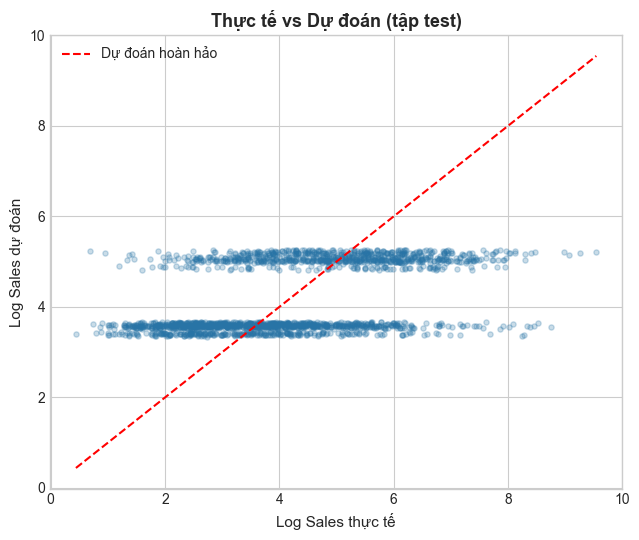

Đã lưu: ../reports/figures/16_actual_vs_predicted.png


In [9]:
os.makedirs("../reports/figures", exist_ok=True)

# 7.1. Thực tế vs Dự đoán
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(y_test, y_pred, alpha=0.25, s=14, color="#2874A6")
lim_min = min(y_test.min(), y_pred.min())
lim_max = max(y_test.max(), y_pred.max())
ax.plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=1.5, label="Dự đoán hoàn hảo")
ax.set_xlabel("Log Sales thực tế", fontsize=11)
ax.set_ylabel("Log Sales dự đoán", fontsize=11)
ax.set_title("Thực tế vs Dự đoán (tập test)", fontsize=13, fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/16_actual_vs_predicted.png", dpi=130, bbox_inches="tight")
plt.show()
print("Đã lưu: ../reports/figures/16_actual_vs_predicted.png")


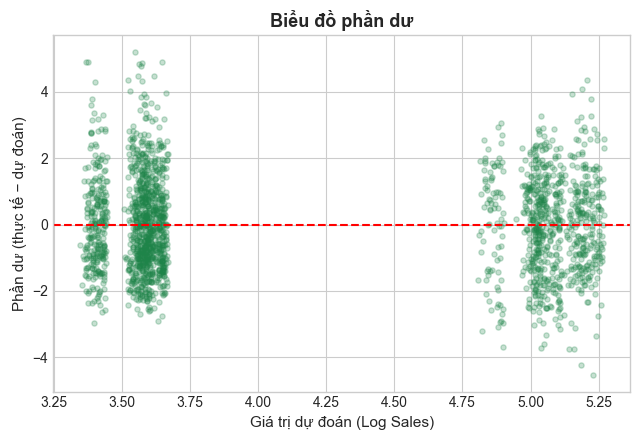

Đã lưu: ../reports/figures/17_residual_plot.png


In [10]:
# 7.2. Biểu đồ phần dư
residual = y_test.values - y_pred

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(y_pred, residual, alpha=0.25, s=14, color="#1E8449")
ax.axhline(0, color="red", linestyle="--", lw=1.5)
ax.set_xlabel("Giá trị dự đoán (Log Sales)", fontsize=11)
ax.set_ylabel("Phần dư (thực tế − dự đoán)", fontsize=11)
ax.set_title("Biểu đồ phần dư", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/17_residual_plot.png", dpi=130, bbox_inches="tight")
plt.show()
print("Đã lưu: ../reports/figures/17_residual_plot.png")


## 8. Hệ số hồi quy và diễn giải kinh doanh
Hệ số one-hot là **so với nhóm tham chiếu** (mức bị loại khi encode). Dấu dương = log-doanh thu cao hơn nhóm tham chiếu khi các biến khác giữ nguyên.


In [11]:
# Lấy tên đặc trưng sau one-hot + hệ số
ohe = model.named_steps["prep"].named_transformers_["cat"]
feature_names = list(ohe.get_feature_names_out(cat_cols)) + num_cols
coefs = model.named_steps["lr"].coef_
intercept = model.named_steps["lr"].intercept_

coef_df = (
    pd.DataFrame({"Biến": feature_names, "Hệ_số": coefs})
    .assign(Abs=lambda d: d["Hệ_số"].abs())
    .sort_values("Abs", ascending=False)
    .drop(columns="Abs")
    .reset_index(drop=True)
)

print(f"Hệ số chặn (intercept) = {intercept:.4f}")
print("\nBảng hệ số (sắp theo |hệ số| giảm dần):")
display(coef_df)

coef_df.to_csv("../reports/regression_coefficients.csv", index=False)
print("Đã lưu: ../reports/regression_coefficients.csv")


Hệ số chặn (intercept) = 2387733686784.9146

Bảng hệ số (sắp theo |hệ số| giảm dần):


,Biến,Hệ_số
0,Region_Central,-1.221455e+12
1,Region_East,-1.221455e+12
2,Region_South,-1.221455e+12
3,Region_West,-1.221455e+12
4,Segment_Home Office,-1.149589e+12
5,Segment_Consumer,-1.149589e+12
6,Segment_Corporate,-1.149589e+12
7,Category_Office Supplies,-1.669008e+10
8,Category_Furniture,-1.669008e+10
9,Category_Technology,-1.669008e+10


Đã lưu: ../reports/regression_coefficients.csv


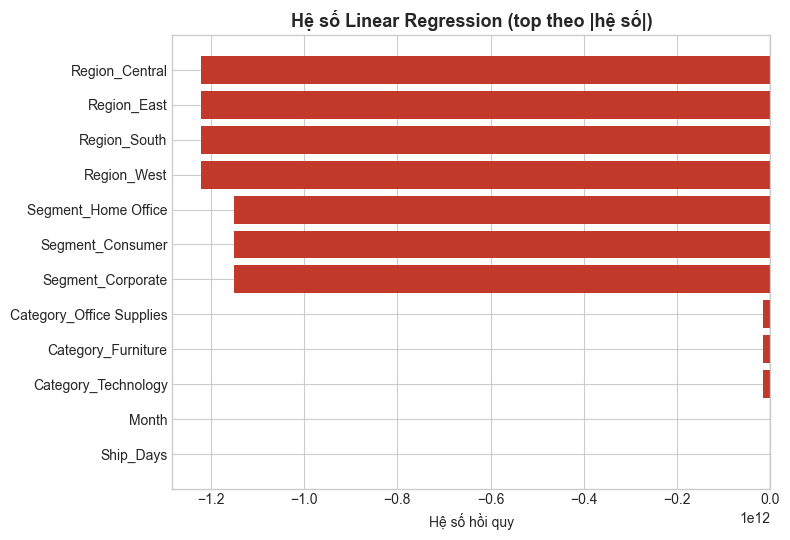

Đã lưu: ../reports/figures/18_regression_coefficients.png


In [12]:
# Biểu đồ hệ số (top theo |hệ số|)
plot_df = coef_df.head(15).iloc[::-1]  # đảo để bar ngang đẹp

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#1E8449" if v > 0 else "#C0392B" for v in plot_df["Hệ_số"]]
ax.barh(plot_df["Biến"], plot_df["Hệ_số"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Hệ số hồi quy")
ax.set_title("Hệ số Linear Regression (top theo |hệ số|)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/18_regression_coefficients.png", dpi=130, bbox_inches="tight")
plt.show()
print("Đã lưu: ../reports/figures/18_regression_coefficients.png")


## 9. Nhận định kinh doanh (điền thêm sau khi xem bảng hệ số)

Chạy xong Bước 8, nhìn vào các dòng có |hệ số| lớn và viết nhận định theo mẫu:

1. **Danh mục (Category)**  
   - Hệ số dương lớn (ví dụ Technology) → đơn thuộc nhóm này có xu hướng log-doanh thu cao hơn nhóm tham chiếu.  
   - → Ưu tiên tồn kho & marketing cho danh mục trụ cột.

2. **Vùng (Region)**  
   - East/West cao hơn South/Central (nếu đúng với hệ số) → phù hợp chẩn đoán doanh thu theo vùng.  
   - → South: tăng số đơn / độ phủ, không chỉ giảm giá.

3. **Phân khúc (Segment)**  
   - Consumer nổi bật → phân tầng CSKH, tập trung nhóm giá trị cao.

4. **Thời gian (Month)**  
   - Hệ số dương về cuối năm → củng cố chiến lược tập trung quý 4.

5. **Ship_Days**  
   - Nếu hệ số nhỏ / gần 0 → số ngày giao chưa phải đòn bẩy chính của doanh thu trong tập này.


## 10. Kết luận và hạn chế

### Kết luận
- Đã xây dựng mô hình **Linear Regression** dự báo `Log_Sales` từ Category, Region, Segment, Month (và Ship_Days nếu có).
- Đã đánh giá trên tập test bằng **R², MAE, RMSE** và lưu biểu đồ actual vs predicted + residual.
- Hệ số hồi quy được dùng để gắn với đề xuất hành động (bảo vệ danh mục trụ cột, chiến lược vùng, thời vụ quý 4).

### Hạn chế
- Mô hình tuyến tính: chưa bắt quan hệ phi tuyến phức tạp.
- One-hot làm số chiều tăng; chưa đưa Sub-Category chi tiết (tránh quá nhiều mức).
- Chưa có giá vốn / biên lợi nhuận → tối ưu theo doanh thu, chưa theo lợi nhuận.
- R² trên thang log cần diễn giải thận trọng khi đổi về Sales gốc.

### Hướng tiếp theo
- Issue #7: Kiểm định ANOVA / t-test theo Region, Category, Segment.
- Issue #8: Cập nhật đề xuất Prescriptive dựa trên hệ số mô hình.
- Issue #9: Bổ sung notebook này vào README (thứ tự chạy 01 → 07).


## Checklist hoàn thành Issue #6

- [x] Chọn biến độc lập phù hợp
- [x] Encode biến categorical (One-Hot Encoding)
- [x] Chia tập train / test (80/20)
- [x] Huấn luyện Linear Regression (scikit-learn)
- [x] Đánh giá: R², RMSE, MAE + residual plot
- [x] Phân tích / giải thích hệ số theo góc nhìn kinh doanh
- [x] Tạo notebook `07_hoi_quy_tuyen_tinh.ipynb`
